# Efficient Uncertainty Quantification and Variance-Based Sensitivity Analysis in Epidemic Modelling Using Polynomial Chaos

__Bjørn C. S. Jensen__, Department of Mathematics and Statistics, University of Helsinki, Helsinki, Finland

__Allan P. Engsig-Karup__, Department of Applied Mathematics and Computer Science, Technical University of Denmark, Kgs. Lyngby, Denmark

__Kim Knudsen__, Department of Applied Mathematics and Computer Science, Technical University of Denmark, Kgs. Lyngby, Denmark

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

This notebook studies Case 1 of [[1]][R1], the time and size of the epidemic peak in a SEIR model of COVID-19 in Denmark. It runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes one to two minutes (most of it the 1000-run quadrature in the comparison section).

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import seir_model as sm

SEED = 2022                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
labels = [r'$\ln R_0$', r'$\ln\tau_{\mathrm{inc}}$', r'$\ln\tau_{\mathrm{inf}}$']
qlabels = [r'$t_{\mathrm{peak}}$ (days)', r'$I_{\mathrm{peak}}$ (individuals)']


def order(v):
    """Order of magnitude of a rounding-level value (4.7e-13 -> '1e-13'); such values change between platforms."""
    return f'1e{int(np.floor(np.log10(abs(v))))}' if v != 0 else '0'

### Summary

Jensen, Engsig-Karup and Knudsen [[1]][R1] propagate uncertainty in the basic reproduction number and the incubation and infectious periods through a SEIR model of the early COVID-19 epidemic in Denmark with polynomial chaos, and report the mean, standard deviation and Sobol indices of the time and size of the epidemic peak. We reimplement the model in Python with exact forward-sensitivity gradients, reproduce the paper's means, standard deviations and Sobol indices, and estimate the active subspaces of both outputs in log coordinates from 1000 samples. Each output has a one-dimensional active subspace ($\lambda_1/\lambda_2 = 1179$ for the peak time and 1065 for the peak size), the peak size is exactly a function of two variables because of a time-scaling symmetry, and the squared weights of the first eigenvector agree with the paper's 1000-run Sobol indices within 0.0013 (largest gap 0.00122).

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

Case 1 of [[1]][R1] (Sec. 4.1, Eq. (4.1), p. 7) is the SEIR model

$$
S' = -\beta\frac{IS}{N},\qquad E' = \beta\frac{IS}{N} - \sigma E,\qquad I' = \sigma E - \gamma I,\qquad R' = \gamma I,
$$

with $N = 5.8\times10^6$, the population of Denmark (p. 7). The uncertain inputs (p. 10) are the basic reproduction number $R_0 = \beta/\gamma$, the incubation period $\tau_{\mathrm{inc}} = 1/\sigma$ and the infectious period $\tau_{\mathrm{inf}} = 1/\gamma$ (days), so $\beta = R_0/\tau_{\mathrm{inf}}$, $\sigma = 1/\tau_{\mathrm{inc}}$, $\gamma = 1/\tau_{\mathrm{inf}}$. The quantities of interest are those of the paper's map (4.2), $F: (R_0,\tau_{\mathrm{inc}},\tau_{\mathrm{inf}}) \mapsto (t_{\mathrm{peak}}, I_{\mathrm{peak}})$: the time $t_{\mathrm{peak}}$ (days after the start) at which the number of infectious individuals $I$ is largest, and $I_{\mathrm{peak}} = I(t_{\mathrm{peak}})$.

**Inputs.** The paper's table on p. 10 gives each input as LogNormal with "mean" 1.4, 4.2, 3.3 and "variance" $0.025^2$, $0.25^2$, $0.25^2$. (The text layer of the PDF drops the superscript and reads 0.0252 and 0.252; the page image shows the squares.) The paper does not say whether these are the moments of the variable or of its logarithm. We read them as the mean and variance of the variable itself, so $\ln x_i \sim N(\mu_i, s_i^2)$ with $s_i^2 = \ln(1 + \mathrm{sd}_i^2/\mathrm{mean}_i^2)$ and $\mu_i = \ln \mathrm{mean}_i - s_i^2/2$. This reading reproduces the paper's published means, standard deviations and Sobol indices (comparison section below). Taking 1.4, 4.2, 3.3 as medians instead moves the mean of $t_{\mathrm{peak}}$ 0.6 day and that of $I_{\mathrm{peak}}$ 0.15 % away from the paper's, and taking $0.025$, $0.25$, $0.25$ as standard deviations of $\ln x$ multiplies the standard deviations of $t_{\mathrm{peak}}$ and $I_{\mathrm{peak}}$ by about 2.8 and 2.2 and makes $R_0$ the least important input (`DATA.md`).

**Initial state.** The paper does not state it. We start with one infectious individual, $(S, E, I, R)(0) = (N-1, 0, 1, 0)$. With $E(0) = 1$ instead, $t_{\mathrm{peak}}$ at the mean inputs would be 3.8 days later (`DATA.md`); with $I(0) = 1$, the 27-point quadrature mean of $t_{\mathrm{peak}}$ is within 0.1 day of the paper's.

**Transform and scaling.** The library's input spaces are uniform or Gaussian, so the analysis is in the log inputs $\mathbf z = \ln\mathbf x$, which are exactly Gaussian, `ac.Gaussian(MU, SIGMA**2)`. Every input is normalized the same way, by its own log-scale mean and standard deviation, $x^{\mathrm{norm}}_i = (z_i - \mu_i)/s_i$. The files hold the physical inputs and the gradients with respect to them; the notebook converts both to log coordinates once, in the cell after loading ($\partial f/\partial z_i = x_i\,\partial f/\partial x_i$).

**Gradients.** `seir_model.py` integrates the forward sensitivities of $(S, E, I)$ with respect to $(\beta, \sigma, \gamma)$ together with the states (12 ODEs, LSODA, rtol $10^{-11}$). The peak is the root of $g = \sigma E - \gamma I = I'$ crossing from positive to negative; there $dt_{\mathrm{peak}}/d\theta = -(\partial g/\partial\theta + \nabla_{\!y} g\cdot \mathbf s_\theta)/(dg/dt)$ and $dI_{\mathrm{peak}}/d\theta = s_{I,\theta}$, since $I' = 0$ at the peak; the chain rule maps $\theta = (\beta,\sigma,\gamma)$ to $\mathbf x$.

**Two exact structures.** Scaling both periods by a factor $c$ (with $R_0$ fixed) scales $\beta$, $\sigma$ and $\gamma$ by $1/c$, which only rescales time, since the initial state does not depend on the rates. So $I_{\mathrm{peak}}$ does not change, $\partial I_{\mathrm{peak}}/\partial z_{\mathrm{inc}} + \partial I_{\mathrm{peak}}/\partial z_{\mathrm{inf}} = 0$, and $t_{\mathrm{peak}}$ scales by $c$, $\partial t_{\mathrm{peak}}/\partial z_{\mathrm{inc}} + \partial t_{\mathrm{peak}}/\partial z_{\mathrm{inf}} = t_{\mathrm{peak}}$. The first makes the third eigenvalue of $\mathbf C$ for $I_{\mathrm{peak}}$ exactly zero.

The input table below is built from `seir_model.py`, with the outputs at the input means.

In [2]:
med = np.exp(sm.MU)
print(f"{'input':8s} {'units':6s} {'mean':>5s} {'sd':>6s} {'mu = E[ln x]':>13s} {'s = sd(ln x)':>13s} {'median':>8s}  description (source: p. 10)")
for j, n in enumerate(sm.NAMES):
    print(f'{n:8s} {sm.UNITS[j]:6s} {sm.MEAN[j]:5.1f} {sm.SD[j]:6.3f} {sm.MU[j]:13.6f} {sm.SIGMA[j]:13.6f} '
          f'{med[j]:8.4f}  {sm.DESCRIPTIONS[j]}')
print(f'\nN = {sm.N_POP:.1e}; (S, E, I)(0) = {sm.Y0.tolist()}; LSODA rtol = {sm.RTOL:g}, atol = {sm.ATOL:g}')
tp0, ip0 = sm.peak(sm.MEAN)
print(f'at the input means: t_peak = {tp0:.3f} days, I_peak = {ip0:.1f} ({100 * ip0 / sm.N_POP:.3f} % of N)')

input    units   mean     sd  mu = E[ln x]  s = sd(ln x)   median  description (source: p. 10)
R0       -        1.4  0.025      0.336313      0.017856   1.3998  basic reproduction number beta/gamma
tau_inc  days     4.2  0.250      1.433316      0.059471   4.1926  mean incubation period 1/sigma (time in E)
tau_inf  days     3.3  0.250      1.191061      0.075649   3.2906  mean infectious period 1/gamma (time in I)

N = 5.8e+06; (S, E, I)(0) = [5799999.0, 0.0, 1.0]; LSODA rtol = 1e-11, atol = 1e-09
at the input means: t_peak = 284.091 days, I_peak = 115582.6 (1.993 % of N)


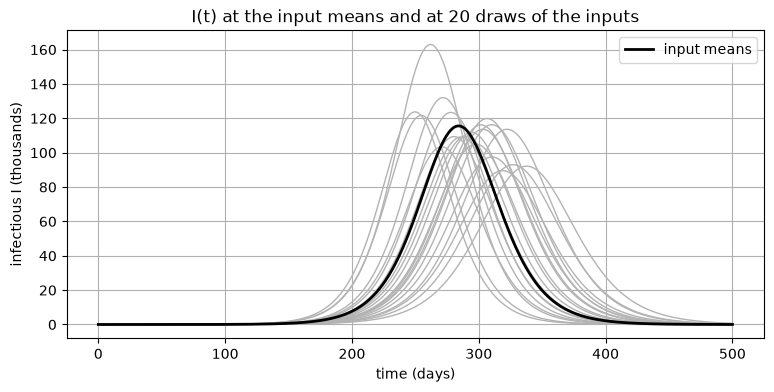

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
t = np.linspace(0, 500, 1001)
for x in np.exp(sm.MU + sm.SIGMA * np.random.default_rng(SEED).standard_normal((20, 3))):
    ax.plot(t, sm.trajectory(x, t)[2] / 1e3, color='0.7', lw=1)
ax.plot(t, sm.trajectory(sm.MEAN, t)[2] / 1e3, 'k', lw=2, label='input means')
ax.set_xlabel('time (days)')
ax.set_ylabel('infectious I (thousands)')
ax.set_title('I(t) at the input means and at 20 draws of the inputs')
ax.legend()
ax.grid(True)
plt.close(fig)
fig

### Load data

`generate_data.py` drew $M = 1000$ samples of the inputs (seed 2022) and wrote the physical inputs, the two outputs, and their exact gradients with respect to the physical inputs (see `DATA.md`).

In [4]:
X = np.loadtxt('inputs.csv', delimiter=',')                       # (M, 3) R0, tau_inc, tau_inf
f = np.loadtxt('outputs.csv', delimiter=',')                      # (M, 2) t_peak (days), I_peak
G = np.loadtxt('gradients.csv', delimiter=',').reshape(-1, 2, 3)  # (M, 2, 3) d(t_peak, I_peak)/dx
print(f'inputs {X.shape}, outputs {f.shape}, gradients {G.shape}')

inputs (1000, 3), outputs (1000, 2), gradients (1000, 2, 3)


The analysis works in log coordinates. This is the one cell that converts: $\mathbf Z = \ln\mathbf X$ and $\partial f/\partial z_i = x_i\,\partial f/\partial x_i$. We then check the files against the model at five samples, check the gradients there against central differences in $\mathbf z$ (step $10^{-5}$), and check the two exact relations above at all 1000 samples.

In [5]:
Z = np.log(X)                    # log inputs, the coordinates of the analysis
Gz = G * X[:, None, :]           # (M, 2, 3) gradients with respect to z = ln x

rows = [0, 1, 2, 3, 4]
f5 = sm.peaks(X[rows])
h = 1e-5
err_fd = []
for i in rows:
    Gfd = np.column_stack([(np.array(sm.peak(np.exp(Z[i] + h * e))) - np.array(sm.peak(np.exp(Z[i] - h * e)))) / (2 * h)
                           for e in np.eye(3)])
    err_fd.append(np.linalg.norm(Gfd - Gz[i], axis=1) / np.linalg.norm(Gz[i], axis=1))
print(f'model vs outputs.csv at rows {rows}: max relative difference {np.max(np.abs(f5 - f[rows]) / f[rows]):.1e}')
print(f'gradients vs central differences in z: max relative error t_peak {np.max(err_fd, axis=0)[0]:.1e}, '
      f'I_peak {np.max(err_fd, axis=0)[1]:.1e}')
r_t = np.abs(Gz[:, 0, 1] + Gz[:, 0, 2] - f[:, 0]) / f[:, 0]
r_I = np.abs(Gz[:, 1, 1] + Gz[:, 1, 2]) / np.linalg.norm(Gz[:, 1], axis=1)
print(f'time scaling, all {len(X)} samples: max |dt/dz_inc + dt/dz_inf - t_peak| / t_peak = {r_t.max():.1e}; '
      f'max |dI/dz_inc + dI/dz_inf| / |grad_z I| = {r_I.max():.1e}')
print(f'R0 in [{X[:, 0].min():.4f}, {X[:, 0].max():.4f}]: samples with R0 <= 1 (no epidemic): {(X[:, 0] <= 1).sum()}; '
      f'tau_inc in [{X[:, 1].min():.3f}, {X[:, 1].max():.3f}], tau_inf in [{X[:, 2].min():.3f}, {X[:, 2].max():.3f}] days')
print(f't_peak in [{f[:, 0].min():.2f}, {f[:, 0].max():.2f}] days, I_peak in [{f[:, 1].min():.0f}, {f[:, 1].max():.0f}]')

model vs outputs.csv at rows [0, 1, 2, 3, 4]: max relative difference 1.3e-10
gradients vs central differences in z: max relative error t_peak 2.4e-07, I_peak 7.4e-07
time scaling, all 1000 samples: max |dt/dz_inc + dt/dz_inf - t_peak| / t_peak = 1.6e-10; max |dI/dz_inc + dI/dz_inf| / |grad_z I| = 7.6e-11
R0 in [1.3284, 1.4861]: samples with R0 <= 1 (no epidemic): 0; tau_inc in [3.481, 4.981], tau_inf in [2.569, 4.311] days
t_peak in [225.56, 348.68] days, I_peak in [82333, 162965]


The model reproduces the stored outputs to a relative $1.3\times10^{-10}$; the files were written by the solve with sensitivities (12 equations) and the check uses the solve without them (3 equations), so the two differ at the level of the ODE tolerance. The gradients agree with central differences to $7.4\times10^{-7}$, the size of the differences' own truncation and solver error (`DATA.md` checks the sensitivities against a tighter solve, to $1.3\times10^{-10}$). The two time-scaling relations hold at every sample to $1.6\times10^{-10}$ and $7.6\times10^{-11}$. No sample is outside the model's meaning: $R_0$ ranges over $[1.3284, 1.4861]$, so every sample has an epidemic with a peak, and both periods stay between 2.569 and 4.981 days.

### Estimate the subspace

The model is cheap and smooth and we have exact gradients, so we use the gradient-based estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i \nabla f_i^T$ in normalized coordinates, separately for $t_{\mathrm{peak}}$ and $I_{\mathrm{peak}}$. The input space is `ac.Gaussian` with mean $\boldsymbol\mu$ and variances $\mathbf s^2$ on the **log** inputs; we pass $\mathbf Z$ and the gradients with respect to $\mathbf z$, and the library maps both to normalized coordinates (the normalized gradient is $s_i\,\partial f/\partial z_i$). We use 500 bootstrap replicates, the library's eigenvalue-gap rule for the dimension, and orient each eigenvector so that the output increases along $\mathbf w_1$ (`ac.orient`, by the covariance of $\mathbf w_1^T\mathbf x$ with $f$).

In [6]:
space = ac.Gaussian(sm.MU, sm.SIGMA**2, names=[f'ln {n}' for n in sm.NAMES])
subs, k_nz = [], []
for q in range(2):
    sub = ac.active_subspace(space=space, X=Z, f=f[:, q], grads=Gz[:, q], estimator='as', nboot=500, rng=SEED)
    sub = ac.orient(sub, by='covariance', X=Z, f=f[:, q], columns=3)
    subs.append(sub)
    lam = sub.eigenvalues
    ks, crit, k_hat = ac.dimension_criterion(sub, rule='evg')
    tol = len(lam) * np.finfo(float).eps * lam[0]      # round-off level of the eigenvalues of C-hat
    k0 = int(np.sum(np.abs(lam) > tol))                 # eigenvalues above round-off
    k_nz.append(k0)
    msg = f'{sm.QOI_NAMES[q]}: eigenvalues {np.array2string(lam[:k0], precision=4)}'
    for k in range(k0, len(lam)):
        msg += (f', lambda_{k + 1} numerically zero (of order {order(lam[k])} in this run, '
                f'below the round-off level m eps lambda_1 = {tol:.0e})')
    msg += f'; n = {sub.n} (gap rule {k_hat}); lambda_1/lambda_2 = {lam[0] / lam[1]:.0f}'
    if k0 == len(lam):
        msg += f', lambda_2/lambda_3 = {lam[1] / lam[2]:.3g}'
    print(msg)

t_peak: eigenvalues [3.9455e+02 3.3478e-01 1.8484e-01]; n = 1 (gap rule 1); lambda_1/lambda_2 = 1179, lambda_2/lambda_3 = 1.81


I_peak: eigenvalues [1.5792e+08 1.4831e+05], lambda_3 numerically zero (of order 1e-13 in this run, below the round-off level m eps lambda_1 = 1e-07); n = 1 (gap rule 1); lambda_1/lambda_2 = 1065


### Results

**Eigenvalues.** The figure shows the eigenvalues with 95 % bootstrap bands, $t_{\mathrm{peak}}$ left and $I_{\mathrm{peak}}$ right.

t_peak: lambda_1 95 % bootstrap interval [390.3, 398.4]; lambda_1/lambda_2 over the replicates: 2.5-97.5 % [1076, 1286]
I_peak: lambda_1 95 % bootstrap interval [1.566e+08, 1.594e+08]; lambda_1/lambda_2 over the replicates: 2.5-97.5 % [964, 1173]


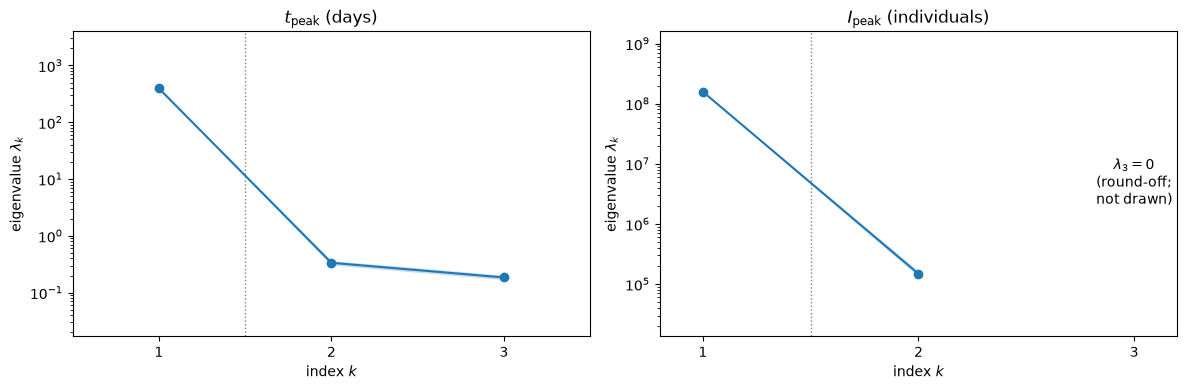

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for q in range(2):
    ac.plotting.plot_eigenvalues(subs[q], ax=axes[q], k_max=k_nz[q])
    axes[q].set_title(qlabels[q])
    if k_nz[q] < 3:   # a numerically zero eigenvalue has no meaningful place on a log axis
        axes[q].set_xlim(0.8, 3.2)
        axes[q].text(3, np.sqrt(subs[q].eigenvalues[0] * subs[q].eigenvalues[1]), r'$\lambda_3 = 0$' + '\n(round-off;\nnot drawn)',
                     ha='center', va='center')
fig.tight_layout()
plt.close(fig)
lo, hi = [], []
for q in range(2):
    b = subs[q].bootstrap_eigenvalues
    print(f'{sm.QOI_NAMES[q]}: lambda_1 95 % bootstrap interval [{np.percentile(b[:, 0], 2.5):.4g}, {np.percentile(b[:, 0], 97.5):.4g}]; '
          f'lambda_1/lambda_2 over the replicates: 2.5-97.5 % [{np.percentile(b[:, 0] / b[:, 1], 2.5):.0f}, {np.percentile(b[:, 0] / b[:, 1], 97.5):.0f}]')
fig

For $t_{\mathrm{peak}}$, $\lambda_1 = 394.55$ (bootstrap interval $[390.3, 398.4]$), $\lambda_2 = 0.335$ and $\lambda_3 = 0.185$, so $\lambda_1/\lambda_2 = 1179$ (1076–1286 over the bootstrap replicates). For $I_{\mathrm{peak}}$, $\lambda_1 = 1.579\times10^8$, $\lambda_2 = 1.483\times10^5$ and $\lambda_1/\lambda_2 = 1065$ (964–1173); its $\lambda_3$ is numerically zero: it is of order $10^{-13}$ in this run, below the round-off level $m\,\varepsilon\,\lambda_1 \approx 10^{-7}$, so its computed value is rounding error of an exact zero (the time-scaling symmetry) and changes with the eigensolver and platform. The ratio $\lambda_2/\lambda_3$ is therefore not a measured gap and is not reported, and the plot draws only $\lambda_1$ and $\lambda_2$ for $I_{\mathrm{peak}}$. The gap rule picks $n = 1$ for both outputs.

t_peak: bootstrap mean subspace distance, k = 1: 0.001, k = 2: 0.042
I_peak: bootstrap mean subspace distance, k = 1: 0.00076, k = 2: of order 1e-11 (round-off)


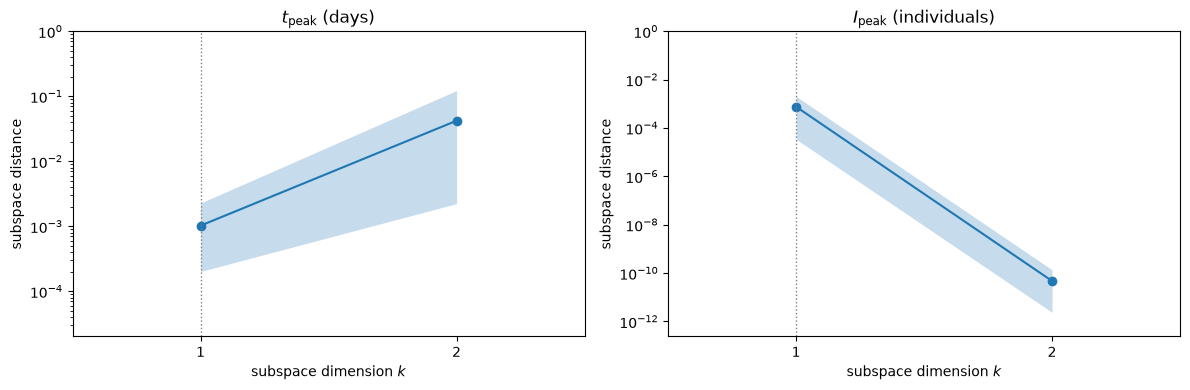

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for q in range(2):
    ac.plotting.plot_subspace_errors(subs[q], ax=axes[q])
    axes[q].set_title(qlabels[q])
    dist = subs[q].bootstrap_distances.mean(axis=0)
    print(f'{sm.QOI_NAMES[q]}: bootstrap mean subspace distance, ' +
          ', '.join(f'k = {k + 1}: ' + (f'{d:.2g}' if d > 1e-8 else f'of order {order(d)} (round-off)')
                    for k, d in enumerate(dist)))
fig.tight_layout()
plt.close(fig)
fig

The bootstrap mean subspace distance of the one-dimensional subspace is 0.001 for $t_{\mathrm{peak}}$ and $7.6\times10^{-4}$ for $I_{\mathrm{peak}}$, so $\mathbf w_1$ is well determined by 1000 samples. For $I_{\mathrm{peak}}$ the two-dimensional subspace has distance of order $10^{-11}$, which is round-off: it is the exact orthogonal complement of the time-scaling direction in every replicate.

t_peak: w1 = [-0.7345  0.4651  0.4942], w2 = [ 0.2853 -0.4491  0.8467], w3 = [0.6157 0.7629 0.1972]
I_peak: w1 = [ 0.8684 -0.3065  0.3899], w2 = [-0.4959 -0.5367  0.6827], w3 = [0.     0.7862 0.618 ]
  I_peak: |w3[1]| is of order 1e-11 (round-off of an exact 0)
I_peak: time-scaling direction d = (0, 1/s_inc, 1/s_inf)/norm = [0.     0.7862 0.618 ]; |w3 . d| = 1.000000000000


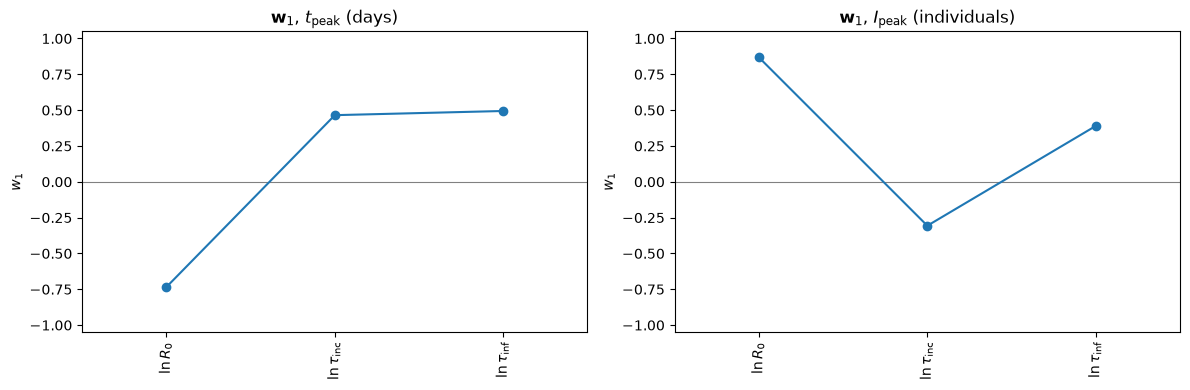

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for q in range(2):
    ac.plotting.plot_eigenvectors(subs[q], indices=[0], labels=labels, ax=[axes[q]])
    axes[q].set_title(r'$\mathbf{w}_1$, ' + qlabels[q])
fig.tight_layout()
plt.close(fig)
for q in range(2):
    W = subs[q].W
    Wp = np.where(np.abs(W) < 1e-8, 0.0, W)            # entries below 1e-8 (round-off) printed as 0
    print(f'{sm.QOI_NAMES[q]}: w1 = {np.array2string(Wp[:, 0], precision=4)}, w2 = {np.array2string(Wp[:, 1], precision=4)}, '
          f'w3 = {np.array2string(Wp[:, 2], precision=4)}')
    for i, k in zip(*np.nonzero((np.abs(W) < 1e-8) & (W != 0))):
        print(f'  {sm.QOI_NAMES[q]}: |w{k + 1}[{i + 1}]| is of order {order(W[i, k])} (round-off of an exact 0)')
null = np.array([0, 1 / sm.SIGMA[1], 1 / sm.SIGMA[2]])
null /= np.linalg.norm(null)
print(f'I_peak: time-scaling direction d = (0, 1/s_inc, 1/s_inf)/norm = {np.array2string(null, precision=4)}; '
      f'|w3 . d| = {abs(subs[1].W[:, 2] @ null):.12f}')
fig

In normalized log coordinates, $t_{\mathrm{peak}}$ increases along $\mathbf w_1 = (-0.7345, 0.4651, 0.4942)$: a larger $R_0$ brings the peak earlier, and longer incubation or infectious periods delay it. $I_{\mathrm{peak}}$ increases along $\mathbf w_1 = (0.8684, -0.3065, 0.3899)$: a larger $R_0$ and a longer infectious period raise the peak, and a longer incubation period lowers it. The third eigenvector for $I_{\mathrm{peak}}$, $(0, 0.7862, 0.618)$ (its first entry is of order $10^{-11}$, round-off of an exact zero), is the time-scaling direction $(0, 1/s_{\mathrm{inc}}, 1/s_{\mathrm{inf}})/\lVert\cdot\rVert$ to twelve digits ($|\mathbf w_3\cdot\mathbf d| = 1.000000000000$): moving both periods by the same factor does not change the peak size.

t_peak: y = w1^T x in [-3.34, 2.88]; corr(y, f) = 0.99782
I_peak: y = w1^T x in [-2.94, 3.39]; corr(y, f) = 0.99872


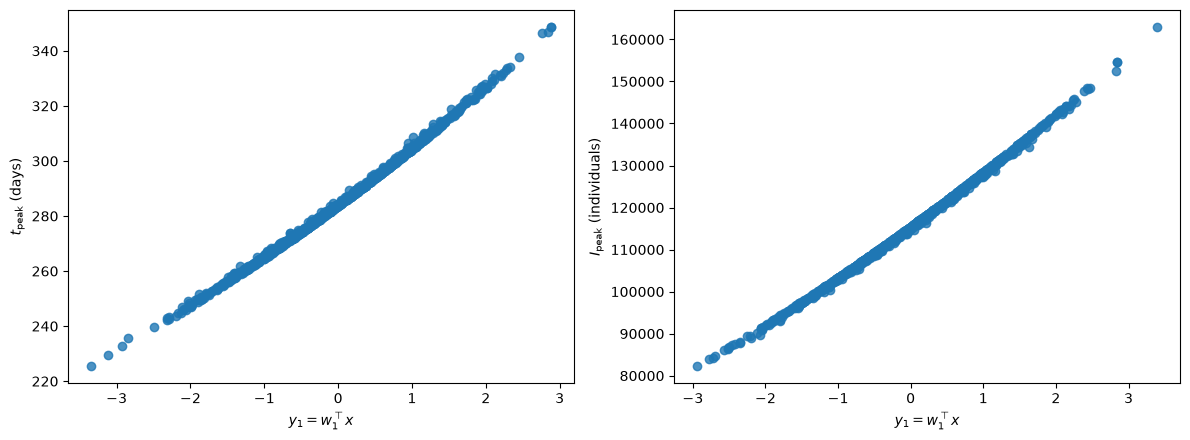

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for q in range(2):
    ac.plotting.plot_sufficient_summary(subs[q], X=Z, f=f[:, q], dims=1, qoi_label=qlabels[q], ax=axes[q])
fig.tight_layout()
plt.close(fig)
XN = space.to_normalized(Z)
for q in range(2):
    y = XN @ subs[q].W[:, 0]
    print(f'{sm.QOI_NAMES[q]}: y = w1^T x in [{y.min():.2f}, {y.max():.2f}]; corr(y, f) = {np.corrcoef(y, f[:, q])[0, 1]:.5f}')
fig

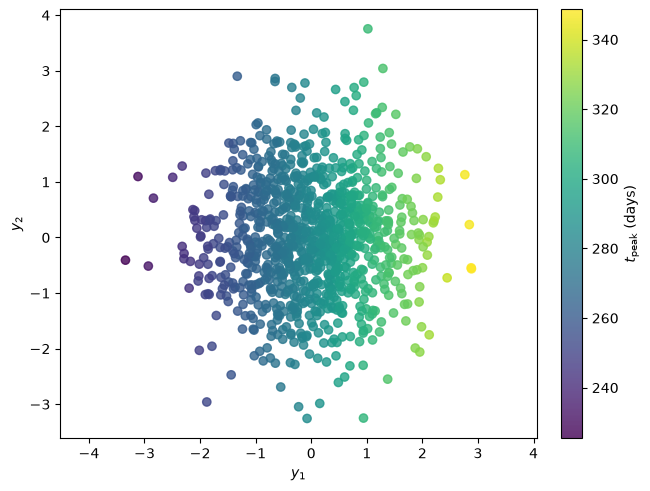

In [11]:
fig, ax = ac.plotting.plot_sufficient_summary(ac.with_dimension(subs[0], 2), X=Z, f=f[:, 0], dims=2,
                                              qoi_label=qlabels[0])
plt.close(fig)
fig

Both one-dimensional summary plots show a tight, slightly convex trend, with $\mathrm{corr}(y, f) = 0.99782$ for $t_{\mathrm{peak}}$ and 0.99872 for $I_{\mathrm{peak}}$; the active variable spans $[-3.34, 2.88]$ and $[-2.94, 3.39]$. In the two-dimensional plot for $t_{\mathrm{peak}}$ the colour changes along $y_1$ and hardly along $y_2$, as $\lambda_2/\lambda_1 = 1/1179$ says it should.

#### Surrogates on the active variables

We fit polynomials in the first active variable (degrees 1 and 2) and, for comparison, a quadratic in the first two, and report the leave-one-out $R^2$.

t_peak  linear, n = 1     LOO R^2 = 0.99561
t_peak  quadratic, n = 1  LOO R^2 = 0.99912
t_peak  quadratic, n = 2  LOO R^2 = 0.99964
I_peak  linear, n = 1     LOO R^2 = 0.99741
I_peak  quadratic, n = 1  LOO R^2 = 0.99947
I_peak  quadratic, n = 2  LOO R^2 = 1.00000


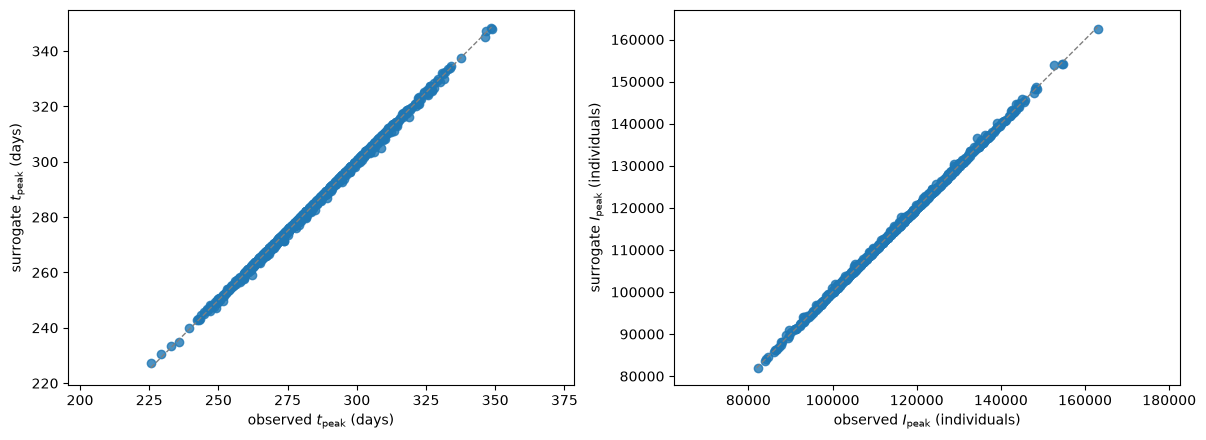

In [12]:
surs = {}
for q in range(2):
    for name, sub_k, deg in [('linear, n = 1', subs[q], 1), ('quadratic, n = 1', subs[q], 2),
                             ('quadratic, n = 2', ac.with_dimension(subs[q], 2), 2)]:
        s = ac.fit_surrogate(X=Z, f=f[:, q], subspace=sub_k, kind='poly', degree=deg)
        surs[q, name] = s
        print(f'{sm.QOI_NAMES[q]:7s} {name:17s} LOO R^2 = {s.loo_r_squared:.5f}')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for q in range(2):
    ac.plotting.plot_surrogate_fit(surs[q, 'quadratic, n = 1'], X=Z, f=f[:, q], qoi_label=qlabels[q], ax=axes[q])
fig.tight_layout()
plt.close(fig)
fig

A quadratic in the single active variable has leave-one-out $R^2 = 0.99912$ for $t_{\mathrm{peak}}$ and 0.99947 for $I_{\mathrm{peak}}$ (a line: 0.99561 and 0.99741), so one variable carries almost all of each output. A quadratic in two active variables raises these to 0.99964 and 1.00000 (to five decimals); for $I_{\mathrm{peak}}$ two active variables are exact, and what is left is the quadratic's approximation error.

### Comparison with the paper

The paper [[1]][R1] does not compute an active subspace. It propagates the input distributions with generalized polynomial chaos (gPC) on tensor Gauss–Hermite quadrature, 3 points per input (27 runs) and 10 points per input (1000 runs), and reports the mean and standard deviation of both outputs (table, p. 10) and the Sobol indices (Fig. 5, p. 9, values printed on the bars). `seir_model.gauss_hermite_moments` repeats that computation with our model: the same quadrature in $\xi = (\ln x - \mu)/s$ and a tensor Hermite expansion of degree $n_q - 1$ per input, with the Sobol indices read off the expansion coefficients [[4]][R4] as in the paper's Sec. 3.2. We also give Monte Carlo estimates from the 1000 stored samples with 95 % intervals, and compare the Sobol indices with the normalized activity scores $\alpha_i/\sum_j\alpha_j$, $\alpha_i = \sum_k \lambda_k w_{ik}^2$ [[3]][R3]: for a function that is close to linear in independent Gaussian inputs, both are close to $w_{1i}^2$. The 1000-run quadrature takes most of the notebook's run time.

In [13]:
t0 = time.perf_counter()
gh3 = sm.gauss_hermite_moments(3)
gh10 = sm.gauss_hermite_moments(10)
print(f'gPC runs: {gh3["runs"]} + {gh10["runs"]}, {time.perf_counter() - t0:.0f} s')
Mn = len(f)
mc_mean, mc_sd = f.mean(axis=0), f.std(axis=0, ddof=1)
mc_mean_hw = 1.96 * mc_sd / np.sqrt(Mn)
# 95 % interval for the standard deviation from the chi-square approximation (normal-theory)
from scipy.stats import chi2
sd_lo = mc_sd * np.sqrt((Mn - 1) / chi2.ppf(0.975, Mn - 1))
sd_hi = mc_sd * np.sqrt((Mn - 1) / chi2.ppf(0.025, Mn - 1))
paper = {'t_peak': {'27': (284.78, 19.89), '1000': (284.84, 19.90), 'S1_27': (0.541, 0.217, 0.240), 'S1_1000': (0.539, 0.216, 0.243)},
         'I_peak': {'27': (115.63e3, 12.56e3), '1000': (115.64e3, 12.56e3), 'S1_27': (0.753, 0.094, 0.152), 'S1_1000': (0.753, 0.094, 0.152)}}
for q, name in enumerate(sm.QOI_NAMES):
    s = 1 if q == 0 else 1e3
    u = 'days' if q == 0 else 'x 10^3'
    p = paper[name]
    print(f'\n{name} ({u}):')
    print(f'  gPC 27 runs:   mean {gh3["mean"][q] / s:.2f} (paper {p["27"][0] / s:.2f}), sd {gh3["std"][q] / s:.2f} (paper {p["27"][1] / s:.2f})')
    print(f'  gPC 1000 runs: mean {gh10["mean"][q] / s:.2f} (paper {p["1000"][0] / s:.2f}), sd {gh10["std"][q] / s:.2f} (paper {p["1000"][1] / s:.2f})')
    print(f'  Monte Carlo, M = {Mn}: mean {mc_mean[q] / s:.2f} +- {mc_mean_hw[q] / s:.2f}, sd {mc_sd[q] / s:.2f} '
          f'(95 % interval [{sd_lo[q] / s:.2f}, {sd_hi[q] / s:.2f}])')
    alpha = ac.activity_scores(subs[q], n=3)
    print(f'  first-order Sobol, gPC 27:   {np.array2string(gh3["S1"][q], precision=3)} (paper Fig. 5A {p["S1_27"]})')
    print(f'  first-order Sobol, gPC 1000: {np.array2string(gh10["S1"][q], precision=3)} (paper Fig. 5B {p["S1_1000"]})')
    print(f'  total Sobol, gPC 1000:       {np.array2string(gh10["ST"][q], precision=3)}; '
          f'interactions 1 - sum S1 = {1 - gh10["S1"][q].sum():.4f}')
    print(f'  normalized activity scores:  {np.array2string(alpha / alpha.sum(), precision=3)}; '
          f'w1^2 = {np.array2string(subs[q].W[:, 0]**2, precision=3)}')
    S1p, w1sq, an = np.array(p['S1_1000']), subs[q].W[:, 0]**2, alpha / alpha.sum()
    print(f'  unrounded: S1 gPC 1000 {np.array2string(gh10["S1"][q], precision=5)}, w1^2 {np.array2string(w1sq, precision=5)}')
    print(f'  largest gap: |S1 gPC 1000 - Fig. 5B| {np.abs(gh10["S1"][q] - S1p).max():.5f}, |w1^2 - Fig. 5B| {np.abs(w1sq - S1p).max():.5f}, '
          f'|w1^2 - S1 gPC 1000| {np.abs(w1sq - gh10["S1"][q]).max():.5f}, |activity - S1 gPC 1000| {np.abs(an - gh10["S1"][q]).max():.5f}')
    print(f'  27 -> 1000 runs, change in mean: ours {(gh10["mean"][q] - gh3["mean"][q]) / s:.0e}, paper {(p["1000"][0] - p["27"][0]) / s:+.2f}; '
          f'largest change in S1: ours {np.abs(gh10["S1"][q] - gh3["S1"][q]).max():.0e}, '
          f'paper {np.abs(np.array(p["S1_1000"]) - np.array(p["S1_27"])).max():.3f}')
    if q == 0:
        for r, g in [('27', gh3), ('1000', gh10)]:
            print(f'  ours - paper, {r} runs: mean {g["mean"][0] - p[r][0]:+.3f} day, sd {g["std"][0] - p[r][1]:+.3f} day')
    else:
        print(f'  gPC 27 runs, unrounded: mean {gh3["mean"][1] / s:.3f}, sd {gh3["std"][1] / s:.3f} (x 10^3)')

gPC runs: 27 + 1000, 61 s

t_peak (days):
  gPC 27 runs:   mean 284.88 (paper 284.78), sd 19.86 (paper 19.89)
  gPC 1000 runs: mean 284.88 (paper 284.84), sd 19.87 (paper 19.90)
  Monte Carlo, M = 1000: mean 284.53 +- 1.19, sd 19.17 (95 % interval [18.37, 20.05])
  first-order Sobol, gPC 27:   [0.538 0.216 0.244] (paper Fig. 5A (0.541, 0.217, 0.24))
  first-order Sobol, gPC 1000: [0.538 0.216 0.244] (paper Fig. 5B (0.539, 0.216, 0.243))
  total Sobol, gPC 1000:       [0.539 0.217 0.245]; interactions 1 - sum S1 = 0.0012
  normalized activity scores:  [0.539 0.216 0.245]; w1^2 = [0.539 0.216 0.244]
  unrounded: S1 gPC 1000 [0.53817 0.21628 0.24435], w1^2 [0.5395  0.21628 0.24422]
  largest gap: |S1 gPC 1000 - Fig. 5B| 0.00135, |w1^2 - Fig. 5B| 0.00122, |w1^2 - S1 gPC 1000| 0.00133, |activity - S1 gPC 1000| 0.00087
  27 -> 1000 runs, change in mean: ours 3e-05, paper +0.06; largest change in S1: ours 4e-05, paper 0.003
  ours - paper, 27 runs: mean +0.095 day, sd -0.026 day
  ours - pape

| Quantity | Paper value | Notebook value |
|---|---|---|
| $t_{\mathrm{peak}}$ mean, sd (days), gPC 27 runs | 284.78, 19.89 (table p. 10) | 284.88, 19.86 |
| $t_{\mathrm{peak}}$ mean, sd (days), gPC 1000 runs | 284.84, 19.90 (table p. 10) | 284.88, 19.87 |
| $t_{\mathrm{peak}}$ mean, sd (days), sampling | MCMC, 8 runs: 285.01 ± 1.37, 20.28 ± 0.82 | Monte Carlo, $M = 1000$: 284.53 ± 1.19, 19.17 [18.37, 20.05] |
| $I_{\mathrm{peak}}$ mean, sd ($\times10^3$), gPC 27 runs | 115.63, 12.56 (table p. 10) | 115.64, 12.56 |
| $I_{\mathrm{peak}}$ mean, sd ($\times10^3$), gPC 1000 runs | 115.64, 12.56 (table p. 10) | 115.64, 12.56 |
| $I_{\mathrm{peak}}$ mean, sd ($\times10^3$), sampling | MCMC, 8 runs: 115.73 ± 0.67, 12.64 ± 0.27 | Monte Carlo, $M = 1000$: 115.65 ± 0.77, 12.48 [11.96, 13.05] |
| First-order Sobol, $t_{\mathrm{peak}}$ ($R_0$, $\tau_{\mathrm{inc}}$, $\tau_{\mathrm{inf}}$) | 0.541, 0.217, 0.240 (Fig. 5A); 0.539, 0.216, 0.243 (Fig. 5B) | 0.538, 0.216, 0.244 (27 and 1000 runs) |
| First-order Sobol, $I_{\mathrm{peak}}$ | 0.753, 0.094, 0.152 (Figs. 5A and 5B) | 0.753, 0.094, 0.151 (27 and 1000 runs) |
| Normalized activity scores, $t_{\mathrm{peak}}$; $I_{\mathrm{peak}}$ | not reported | 0.539, 0.216, 0.245; 0.754, 0.094, 0.152 |
| Active subspace | not reported | $n = 1$ for both; $\lambda_1/\lambda_2 = 1179$ and 1065 |

With our reading of the input table and $I(0) = 1$, the quadrature reproduces the paper's $I_{\mathrm{peak}}$ mean to the last printed digit (0.01 × 10³) for the 27-run mean (115.64 against 115.63; unrounded 115.641); exactly for the 1000-run row; and the standard deviation (12.56) exactly in both rows. For $t_{\mathrm{peak}}$ our mean is 0.095 day above the paper's 27-run value (0.035 day above its 1000-run value), and our standard deviation is 0.026 day below the 27-run value (0.035 day below the 1000-run value). The authors' initial state, solver and way of locating the peak are not stated, but the paper's own $t_{\mathrm{peak}}$ results show numerical error of this size: from 27 to 1000 runs its mean moves by +0.06 day and its Sobol indices by up to 0.003, while ours, with the peak located as a root of the smooth function $I'$, move by $3\times10^{-5}$ day and $4\times10^{-5}$. The quadrature of a smooth output has converged at 27 nodes, so the paper's 27 → 1000 change points to coarse numerics (solver tolerances or peak location) in the authors' $t_{\mathrm{peak}}$, and our 0.1-day difference is within that size. Our first-order Sobol indices agree with the paper's 1000-run values (Fig. 5B) within 0.0014 in every component (largest gap 0.00135, $\tau_{\mathrm{inf}}$ for $t_{\mathrm{peak}}$). Our Monte Carlo intervals (mean ± 1.96 standard errors; a normal-theory interval for the standard deviation) contain the quadrature values; the paper's MCMC row is a different estimator (eight Metropolis–Hastings chains) and is listed for completeness.

**Sobol indices and activity scores.** The interactions are small ($1 - \sum_i S_i = 0.0012$ for $t_{\mathrm{peak}}$ and 0.0022 for $I_{\mathrm{peak}}$), and each output is nearly linear in the normalized log inputs, which are independent standard Gaussians. For such a function the variance shares, the normalized activity scores and $w_{1i}^2$ all coincide; here $w_{1i}^2$ agrees with our 1000-run first-order Sobol indices within 0.0014 (largest gap 0.00133) and the normalized activity scores within 0.001 (0.00091). So the paper's conclusion that $R_0$ matters most (0.54 of the variance of $t_{\mathrm{peak}}$, 0.75 of $I_{\mathrm{peak}}$) is also the statement that $\mathbf w_1$ points mostly along $\ln R_0$. The active subspace adds the direction: the two periods act on $t_{\mathrm{peak}}$ with the same sign and on $I_{\mathrm{peak}}$ with opposite signs, and the time-scaling direction is exactly inactive for $I_{\mathrm{peak}}$.

### References

[1] B. C. S. Jensen, A. P. Engsig-Karup, and K. Knudsen. [Efficient uncertainty quantification and variance-based sensitivity analysis in epidemic modelling using polynomial chaos](https://doi.org/10.1051/mmnp/2022014). *Mathematical Modelling of Natural Phenomena*, 17:8, 2022. (Preprint: arXiv:2109.08066.) The authors' MATLAB code is at <https://gitlab.gbar.dtu.dk/bcsj/covid-19-ctrl-public-code> (not reachable when this notebook was built; not used).

[2] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[3] P. G. Constantine and P. Diaz. [Global sensitivity metrics from active subspaces](https://doi.org/10.1016/j.ress.2017.01.013). *Reliability Engineering & System Safety*, 162:1–13, 2017.

[4] B. Sudret. [Global sensitivity analysis using polynomial chaos expansions](https://doi.org/10.1016/j.ress.2007.04.002). *Reliability Engineering & System Safety*, 93(7):964–979, 2008.

[R1]: https://doi.org/10.1051/mmnp/2022014
[R2]: https://doi.org/10.1137/1.9781611973860
[R3]: https://doi.org/10.1016/j.ress.2017.01.013
[R4]: https://doi.org/10.1016/j.ress.2007.04.002

### Acknowledgments

From [[1]][R1]: "This work was supported by the project Estimation, Simulation, and Control for Optimal Containment of COVID 19 from the Novo Nordisk Fonden; project no. NNF20SA0063089 (Application no. 67). BCSJ was supported by the Academy of Finland (grant no. 320022)."

In [14]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 77.4 s
